# NER văn bản Khoa học dữ liệu với spaCy
Quy trình theo `B5/spacy.ipynb`: nhãn **PER / ORG / LOC / MISC / O** như mẫu của thầy; **Label Studio export → spacy_train.json → train `spacy.blank('vi')` → test**, bổ sung chia train/test và đánh giá **Precision / Recall / F1 theo từng thực thể** (slide 09 – Evaluation of NER).

Dữ liệu: 97 câu trích từ Wikipedia tiếng Việt (xem `data/raw/sources.md`).

> Đổi `INPUT_FILE` thành file export thật của nhóm. `MOCK_export.json` chỉ là dữ liệu giả lập từ gazetteer để chạy thử.

In [1]:
INPUT_FILE = "data/export/annotation.json"
OUTPUT_FILE = "data/spacy_train.json"
LANG = "vi"
N_EPOCHS = 30
TEST_RATIO = 0.2
SEED = 42
import os; os.chdir(os.path.abspath(".."))  if os.path.basename(os.getcwd()) == "notebooks" else None

## 1. Chuyển file export Label Studio → spacy_train.json (giống code của thầy)

In [2]:
import json

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

spacy_data = []
for item in data:
    text = item["data"]["text"]
    entities = []
    annotation = item["annotations"][0]
    for res in annotation["result"]:
        if res["type"] == "labels":
            entities.append([res["value"]["start"], res["value"]["end"], res["value"]["labels"][0]])
    spacy_data.append({"text": text, "entities": entities})

with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump(spacy_data, f, ensure_ascii=False, indent=2)
print("✅ Done! Saved:", OUTPUT_FILE, "| số câu:", len(spacy_data))

✅ Done! Saved: data/spacy_train.json | số câu: 97


## 2. Đọc lại, bỏ nhãn `O`, thống kê nhãn

In [3]:
from collections import Counter

with open(OUTPUT_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

spacy_data = []
for item in data:
    entities = [(s, e, lab) for s, e, lab in item["entities"] if lab != "O"]
    spacy_data.append((item["text"], {"entities": entities}))

label_count = Counter(lab for _, ann in spacy_data for *_, lab in ann["entities"])
print("Số câu:", len(spacy_data), "| Số thực thể:", sum(label_count.values()))
print(dict(label_count.most_common()))
print(spacy_data[1])

Số câu: 97 | Số thực thể: 295
{'MISC': 196, 'PER': 47, 'ORG': 44, 'LOC': 8}
('Vào tháng 10 năm 2023, mô hình tạo hình ảnh DALL-E 3 của OpenAI đã được tích hợp vào ChatGPT.', {'entities': [(44, 52, 'MISC'), (57, 63, 'ORG'), (85, 92, 'MISC')]})


## 3. Kiểm tra khớp biên token (nguyên nhân cảnh báo W030 trong notebook của thầy)
Thực thể không khớp ranh giới token sẽ bị spaCy **bỏ qua** khi train.

In [4]:
import spacy, warnings
warnings.filterwarnings("ignore", message=r"\[W030\]")

def check_alignment(lang):
    nlp_tmp = spacy.blank(lang)
    bad = []
    for text, ann in spacy_data:
        doc = nlp_tmp.make_doc(text)
        bad += [(text[s:e], lab) for s, e, lab in ann["entities"] if doc.char_span(s, e) is None]
    return bad

for lang in ["vi", "xx"]:
    bad = check_alignment(lang)
    print(f"{lang}: {len(bad)} thực thể lệch biên", bad)

vi: 2 thực thể lệch biên [('NYU', 'ORG'), ('CUDA', 'MISC')]
xx: 1 thực thể lệch biên [('IoU', 'MISC')]


## 4. Chia train / test

In [5]:
import random
random.seed(SEED)
shuffled = spacy_data[:]
random.shuffle(shuffled)
n_test = max(1, int(len(shuffled) * TEST_RATIO))
test_data, train_data = shuffled[:n_test], shuffled[n_test:]
print("Train:", len(train_data), "câu | Test:", len(test_data), "câu")

Train: 78 câu | Test: 19 câu


## 5. Train NER với `spacy.blank` (giống vòng lặp của thầy, thêm shuffle)

In [6]:
from spacy.training import Example
from spacy.util import minibatch, compounding

def train_ner(lang, train_data, n_epochs=N_EPOCHS, verbose=True):
    nlp = spacy.blank(lang)
    ner = nlp.add_pipe("ner")
    for _, ann in train_data:
        for *_, label in ann["entities"]:
            ner.add_label(label)
    examples = [Example.from_dict(nlp.make_doc(t), a) for t, a in train_data]
    optimizer = nlp.initialize(lambda: examples)
    for epoch in range(n_epochs):
        random.shuffle(examples)
        losses = {}
        for batch in minibatch(examples, size=compounding(4.0, 32.0, 1.001)):
            nlp.update(batch, sgd=optimizer, drop=0.2, losses=losses)
        if verbose and (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}, Losses: {losses}")
    return nlp

random.seed(SEED); spacy.util.fix_random_seed(SEED)
nlp = train_ner(LANG, train_data)
nlp.to_disk(f"models/ner_khdl_{LANG}")

Epoch 5, Losses: {'ner': np.float32(202.44876)}


Epoch 10, Losses: {'ner': np.float32(62.33179)}


Epoch 15, Losses: {'ner': np.float32(19.867878)}


Epoch 20, Losses: {'ner': np.float32(11.12238)}


Epoch 25, Losses: {'ner': np.float32(3.339651)}


Epoch 30, Losses: {'ner': np.float32(3.0863695)}


## 6. Đánh giá trên tập test — Precision / Recall / F1 (theo thực thể)

In [7]:
import pandas as pd

def evaluate(nlp, data):
    examples = [Example.from_dict(nlp.make_doc(t), a) for t, a in data]
    return nlp.evaluate(examples)

scores = evaluate(nlp, test_data)
print(f"TỔNG  P={scores['ents_p']:.3f}  R={scores['ents_r']:.3f}  F1={scores['ents_f']:.3f}")
test_count = Counter(lab for _, a in test_data for *_, lab in a["entities"])
per_type = pd.DataFrame(scores["ents_per_type"]).T.rename(columns={"p": "Precision", "r": "Recall", "f": "F1"})
per_type["Support(test)"] = [test_count.get(l, 0) for l in per_type.index]
per_type = per_type.round(3).sort_index()
os.makedirs("results", exist_ok=True)
per_type.to_csv(f"results/ner_per_type_{LANG}.csv")
json.dump({k: scores[k] for k in ["ents_p", "ents_r", "ents_f", "ents_per_type"]},
          open(f"results/ner_metrics_{LANG}.json", "w"), ensure_ascii=False, indent=2)
per_type

TỔNG  P=0.772  R=0.759  F1=0.765


,Precision,Recall,F1,Support(test)
MISC,0.771,0.730,0.750,38
ORG,0.833,0.769,0.800,13
PER,0.700,0.875,0.778,8


## 7. So sánh tokenizer `vi` (pyvi) và `xx`

In [8]:
rows = []
for lang in ["vi", "xx"]:
    random.seed(SEED); spacy.util.fix_random_seed(SEED)
    m = nlp if lang == LANG else train_ner(lang, train_data, verbose=False)
    s = evaluate(m, test_data)
    rows.append({"Tokenizer": lang, "Lệch biên": len(check_alignment(lang)),
                 "Precision": round(s["ents_p"], 3), "Recall": round(s["ents_r"], 3), "F1": round(s["ents_f"], 3)})
compare = pd.DataFrame(rows); compare.to_csv("results/ner_compare_tokenizer.csv", index=False)
compare

,Tokenizer,Lệch biên,Precision,Recall,F1
0,vi,2,0.772,0.759,0.765
1,xx,1,0.705,0.729,0.717


## 8. Phân tích lỗi trên tập test (gold vs dự đoán)

In [9]:
def ents_of(text, ann):
    return {(text[s:e], lab) for s, e, lab in ann["entities"]}

n_err = 0
for text, ann in test_data:
    gold = ents_of(text, ann)
    pred = {(e.text, e.label_) for e in nlp(text).ents}
    if gold != pred:
        n_err += 1
        print("📝", text)
        print("   Thiếu (FN):", sorted(gold - pred))
        print("   Thừa/sai (FP):", sorted(pred - gold))
print(f"\n{n_err}/{len(test_data)} câu test có lỗi")

📝 TensorFlow nguyên thủy được phát triển bởi đội Google Brain cho mục đích nghiên cứu và sản xuất của Google và sau đó được phát hành theo giấy phép mã nguồn mở Apache 2.0 vào ngày 9/11/2015.
   Thiếu (FN): [('Apache 2.0', 'MISC')]
   Thừa/sai (FP): [('Apache', 'MISC')]
📝 Nhiều nhóm tại Google đã chuyển từ DistBelief sang TensorFlow để phục vụ cho việc nghiên cứu và sản xuất.
   Thiếu (FN): [('DistBelief', 'MISC')]
   Thừa/sai (FP): []
📝 Năm 2018, Hinton được trao Giải Turing cùng Yoshua Bengio và Yann LeCun; bộ ba này được mệnh danh là những "Bố già AI" (Godfather of AI) nhờ những đóng góp nền tảng cho lĩnh vực mạng neuron nhân tạo và học sâu.
   Thiếu (FN): [('Giải Turing', 'MISC'), ('Hinton', 'PER')]
   Thừa/sai (FP): [('Giải Turing', 'PER'), ('Godfather', 'ORG'), ('Hinton', 'ORG')]
📝 Điển hình là nhóm nghiên cứu về trí tuệ nhân tạo của Facebook đã tạo ra phần mềm DeepFace có khả năng nhận dạng khuôn mặt tốt như con người với độ chính xác khoảng 97,35%.
   Thiếu (FN): [('DeepFace', 

## 9. Test với câu mới (giống phần `# test` của thầy)

In [10]:
tests = [
    "Năm 2017, Andrew Ng rời Baidu và làm việc tại Stanford.",
    "Nhóm nghiên cứu của Google Brain dùng TensorFlow và Python để huấn luyện mạng LSTM.",
    "Mạng LeNet của Yann LeCun đạt độ chính xác cao trên tập MNIST.",
    "OpenAI có trụ sở tại San Francisco và phát triển ChatGPT.",
    "Mô hình YOLO được đánh giá bằng mAP và IoU trên bộ dữ liệu COCO.",
]
for s in tests:
    doc = nlp(s)
    print(s)
    for ent in doc.ents:
        print("   ", ent.text, "→", ent.label_)

Năm 2017, Andrew Ng rời Baidu và làm việc tại Stanford.
    Andrew → ORG
    Baidu → ORG
    Stanford → ORG
Nhóm nghiên cứu của Google Brain dùng TensorFlow và Python để huấn luyện mạng LSTM.
    Google → ORG
    TensorFlow → MISC
    Python → MISC
    LSTM. → MISC
Mạng LeNet của Yann LeCun đạt độ chính xác cao trên tập MNIST.
    Mạng LeNet → MISC
    Yann LeCun → PER
    độ chính xác → MISC
    MNIST. → MISC
OpenAI có trụ sở tại San Francisco và phát triển ChatGPT.
    OpenAI → ORG
    San Francisco → LOC
    ChatGPT → MISC
Mô hình YOLO được đánh giá bằng mAP và IoU trên bộ dữ liệu COCO.
    YOLO → MISC
    mAP → MISC
    IoU → MISC
    COCO. → PER


In [11]:
from spacy import displacy
displacy.render(nlp(tests[2]), style="ent", jupyter=True)

## 10. Quan hệ giữa các thực thể (Relation)
Đọc các cạnh `type == "relation"` trong file export: mỗi quan hệ nối 2 thực thể (`from_id` → `to_id`).

In [12]:
import matplotlib.pyplot as plt
import numpy as np

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

rel_rows = []
cooc = Counter()
ENT_TYPES = ["PER", "ORG", "LOC", "MISC"]
for item in raw:
    res = item["annotations"][0]["result"]
    spans = {r["id"]: (r["value"]["text"], r["value"]["labels"][0]) for r in res if r["type"] == "labels"}
    types = sorted({lab for _, lab in spans.values() if lab in ENT_TYPES})
    for i, a in enumerate(types):
        for b in types[i:]:
            cooc[(a, b)] += 1
    for r in res:
        if r["type"] == "relation" and r["from_id"] in spans and r["to_id"] in spans:
            (h, ht), (t, tt) = spans[r["from_id"]], spans[r["to_id"]]
            rel_rows.append({"Chủ thể": h, "Loại CT": ht, "Quan hệ": (r.get("labels") or ["?"])[0],
                             "Đối tượng": t, "Loại ĐT": tt})

rel_df = pd.DataFrame(rel_rows)
rel_df.to_csv("results/relations.csv", index=False)
print("Tổng số quan hệ:", len(rel_df))
print(rel_df["Quan hệ"].value_counts().to_string())
rel_df.head(15)

Tổng số quan hệ: 46
Quan hệ
phát_triển      25
cộng_sự          9
sử_dụng          5
làm_việc_tại     3
thuộc_về         3
nằm_ở            1


,Chủ thể,Loại CT,Quan hệ,Đối tượng,Loại ĐT
0,OpenAI,ORG,phát_triển,DALL-E 3,MISC
1,OpenAI,ORG,phát_triển,Codex,MISC
2,OpenAI,ORG,nằm_ở,San Francisco,LOC
3,Yoshua Bengio,PER,cộng_sự,Yann LeCun,PER
4,David Ackley,PER,cộng_sự,Terry Sejnowski,PER
5,Frank Rosenblatt,PER,phát_triển,perceptron,MISC
6,Corinna Cortes,PER,cộng_sự,Vladimir Vapnik,PER
7,Vladimir Vapnik,PER,phát_triển,Support Vector Machine,MISC
8,Sepp Hochreiter,PER,cộng_sự,Jürgen Schmidhuber,PER
9,Jürgen Schmidhuber,PER,phát_triển,Long Short-Term Memory,MISC


## 11. Bản đồ tương quan (correlation map)
- **Trái:** số quan hệ giữa từng cặp loại thực thể (hàng = chủ thể, cột = đối tượng)
- **Phải:** số câu mà hai loại thực thể cùng xuất hiện (đồng xuất hiện)

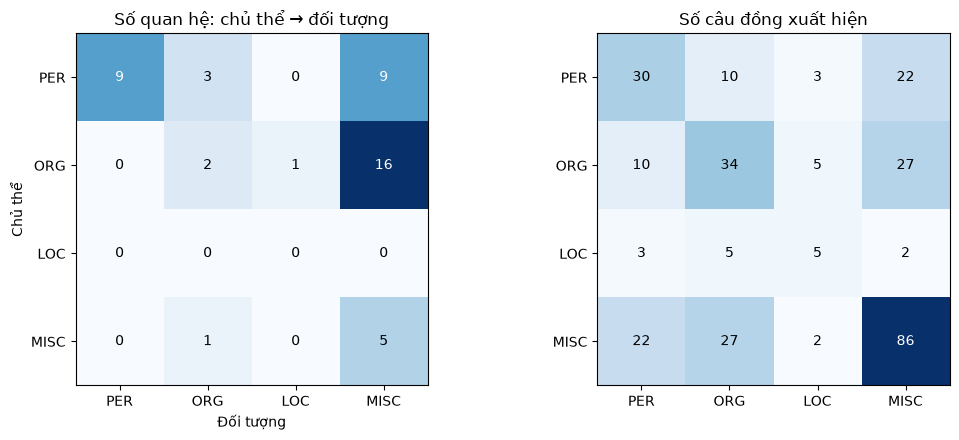

In [13]:
def heat(ax, M, title):
    ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(4), ENT_TYPES); ax.set_yticks(range(4), ENT_TYPES)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, int(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_title(title)

idx = {t: i for i, t in enumerate(ENT_TYPES)}
R = np.zeros((4, 4))
for _, row in rel_df.iterrows():
    if row["Loại CT"] in idx and row["Loại ĐT"] in idx:
        R[idx[row["Loại CT"]], idx[row["Loại ĐT"]]] += 1
C = np.zeros((4, 4))
for (a, b), n in cooc.items():
    C[idx[a], idx[b]] = C[idx[b], idx[a]] = n

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
heat(axes[0], R, "Số quan hệ: chủ thể → đối tượng")
axes[0].set_ylabel("Chủ thể"); axes[0].set_xlabel("Đối tượng")
heat(axes[1], C, "Số câu đồng xuất hiện")
plt.tight_layout(); plt.savefig("results/correlation_map.png", dpi=150); plt.show()

## 12. Đồ thị quan hệ giữa các thực thể

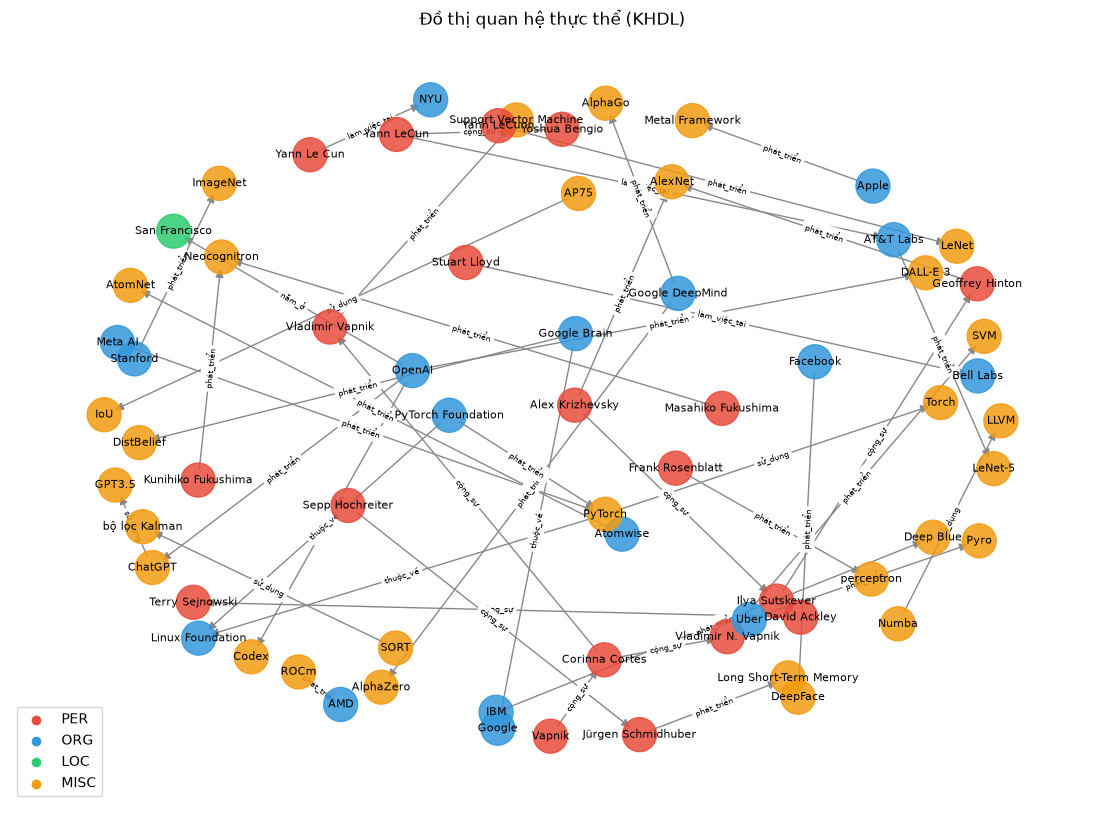

In [14]:
import networkx as nx

G = nx.DiGraph()
for _, row in rel_df.iterrows():
    G.add_node(row["Chủ thể"], t=row["Loại CT"]); G.add_node(row["Đối tượng"], t=row["Loại ĐT"])
    G.add_edge(row["Chủ thể"], row["Đối tượng"], label=row["Quan hệ"])
COLORS = {"PER": "#e74c3c", "ORG": "#3498db", "LOC": "#2ecc71", "MISC": "#f39c12"}
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.9, seed=SEED)
nx.draw_networkx_nodes(G, pos, node_color=[COLORS.get(G.nodes[n]["t"], "#999") for n in G], node_size=600, alpha=0.85)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=12, edge_color="#888")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=6)
for t, c in COLORS.items():
    plt.scatter([], [], c=c, label=t)
plt.legend(loc="lower left"); plt.axis("off")
plt.title("Đồ thị quan hệ thực thể (KHDL)")
plt.savefig("results/relation_graph.png", dpi=150, bbox_inches="tight"); plt.show()